# WeVisOne-VL: Segmentation → Matting

Run one image through pixel-level perception in sequence. **Segmentation** renders a thresholded binary mask; **matting** preserves the model's continuous alpha values and exports an RGBA cutout.

## 1. Load the released model and pixel decoder

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image

from wevisone_vl import WeVisOneVL
from wevisone_vl.visualization import render_overlay, save_result


def find_repo_root() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "wevisone_vl").is_dir() and (candidate / "demo").is_dir():
            return candidate
    raise RuntimeError("Run this notebook from inside the WeVisOne-VL repository.")


repo_root = find_repo_root()
examples_dir = repo_root / "demo" / "examples"
local_checkpoint = repo_root / "checkpoints" / "WeVisOne-VL-4B"
model_path = os.environ.get("WEVISONE_MODEL") or (
    str(local_checkpoint) if local_checkpoint.is_dir() else "tencent/WeVisOne-VL-4B"
)
print(f"Loading WeVisOne-VL from: {model_path}")

model = WeVisOneVL(
    model_path,
    backend="transformers",
    device="auto",
    dtype="bfloat16",
)

Loading WeVisOne-VL from: checkpoints/WeVisOne-VL-4B


## 2. Load one shared image

Image: demo/examples/images/seabreeze.jpg | size=(1620, 1080)


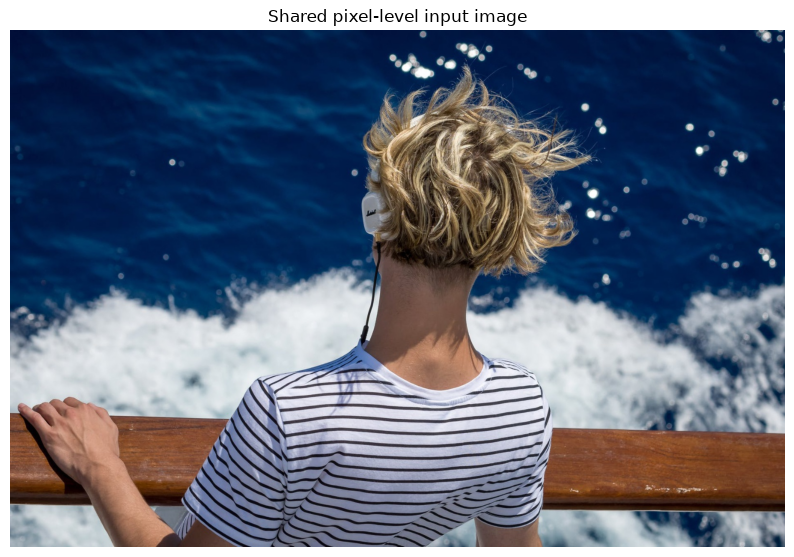

In [2]:
image_path = examples_dir / "images" / "seabreeze.jpg"
image = Image.open(image_path).convert("RGB")
output_root = repo_root / "outputs" / "segmentation_matting_pipeline"
print(f"Image: {image_path} | size={image.size}")

plt.figure(figsize=(10, 7))
plt.imshow(image)
plt.axis("off")
plt.title("Shared pixel-level input image")
plt.show()

## 3. Segmentation

Predict the person mask, threshold it at `0.5`, and render the binary segmentation overlay.

Prompt: Locate the instances that match the following description and provide the alpha mattes: person.
Raw response: <ref>person</ref><box><9><66><752><1000><OBJ></box>
Decoded masks: 1
Latency: 1.74s
Saved overlay: outputs/segmentation_matting_pipeline/01_segmentation/overlay.png


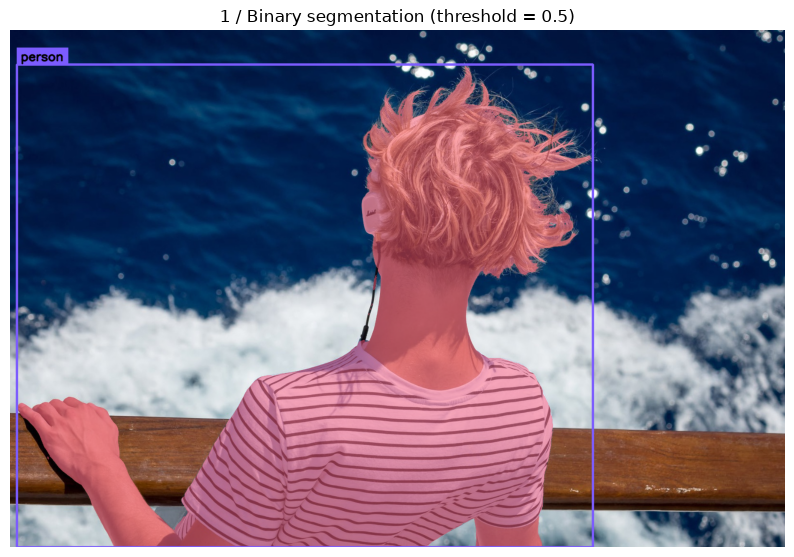

In [3]:
segmentation_result = model.predict(
    image,
    task="segmentation",
    query="person",
    max_new_tokens=4096,
    temperature=0.0,
)
segmentation_paths = save_result(
    output_root / "01_segmentation", image, segmentation_result
)
segmentation_visualization = render_overlay(
    image, segmentation_result, mask_threshold=0.5
)
segmentation_visualization.save(segmentation_paths["overlay"])

print("Prompt:", segmentation_result.prompt)
print("Raw response:", segmentation_result.response)
print("Decoded masks:", len(segmentation_result.masks))
print(f"Latency: {segmentation_result.latency_s:.2f}s")
print("Saved overlay:", segmentation_paths["overlay"])
plt.figure(figsize=(10, 7))
plt.imshow(segmentation_visualization)
plt.axis("off")
plt.title("1 / Binary segmentation (threshold = 0.5)")
plt.show()

## 4. Matting

Predict the person again while retaining continuous alpha values. Display the overlay, alpha matte, and transparent RGBA cutout.

Prompt: Locate the instances that match the following description and provide the alpha mattes: person.
Raw response: <ref>person</ref><box><9><66><752><1000><OBJ></box>
Decoded mattes: 1
Latency: 0.99s
Saved alpha matte: outputs/segmentation_matting_pipeline/02_matting/alpha.png
Saved RGBA cutout: outputs/segmentation_matting_pipeline/02_matting/cutout.png


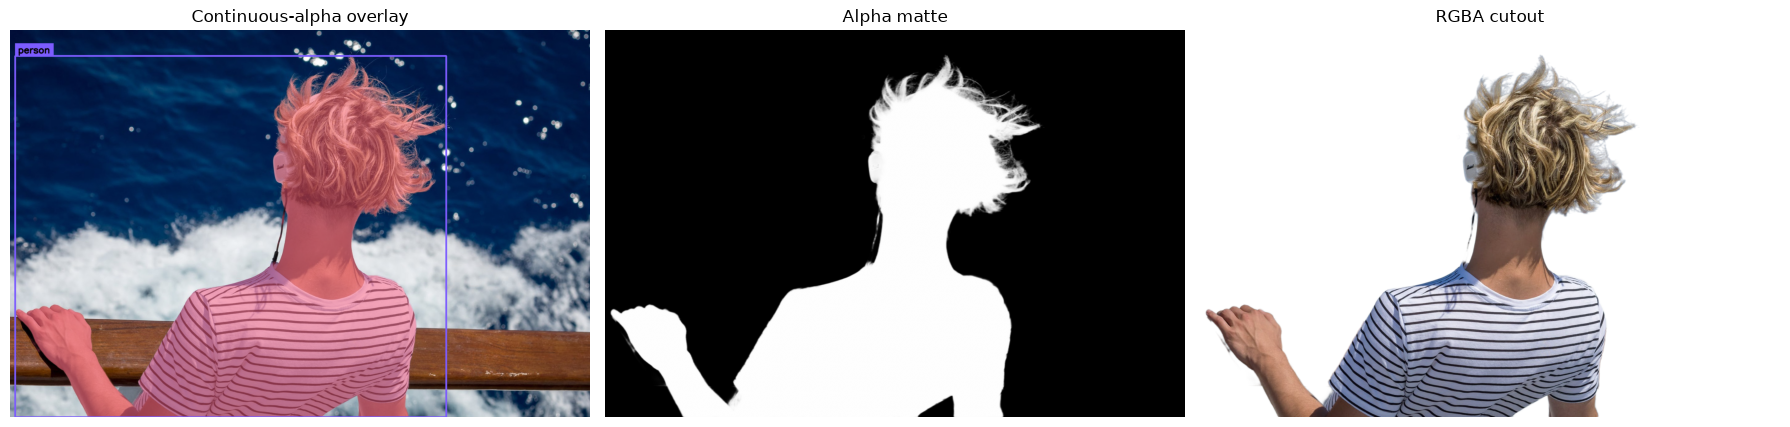

In [4]:
matting_result = model.predict(
    image,
    task="matting",
    query="person",
    max_new_tokens=4096,
    temperature=0.0,
)
matting_paths = save_result(output_root / "02_matting", image, matting_result)
matting_visualization = render_overlay(image, matting_result)
alpha_image = Image.open(matting_paths["alpha"])
cutout_image = Image.open(matting_paths["cutout"])

print("Prompt:", matting_result.prompt)
print("Raw response:", matting_result.response)
print("Decoded mattes:", len(matting_result.masks))
print(f"Latency: {matting_result.latency_s:.2f}s")
print("Saved alpha matte:", matting_paths["alpha"])
print("Saved RGBA cutout:", matting_paths["cutout"])

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(matting_visualization)
axes[0].set_title("Continuous-alpha overlay")
axes[1].imshow(alpha_image, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Alpha matte")
axes[2].imshow(cutout_image)
axes[2].set_title("RGBA cutout")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()